In [10]:
# ============================================================
# A HYBRID MODEL OF AFFECTIVE TRANSITIONS IN TYPE II BIPOLAR DISORDER
# Hybrid multiscale hysteretic model for bipolar II disorder
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass, replace
from typing import Tuple


# ============================================================
# 1. Constants and model parameters
# ============================================================

STATE_D = -1   # D* — modelowy stan depresyjny
STATE_E = 0    # E  — eutymia
STATE_H = 1    # H* — modelowy stan hipomaniakalny

STATE_LABELS = {
    STATE_D: "D*",
    STATE_E: "E",
    STATE_H: "H*",
}


@dataclass(frozen=True)
class ModelParams:
    """
    Parametry hybrydowego modelu dynamiki afektywnej.

    z_t — ukryty stan afektywny (latent affective state)
    y_t — obserwowany pomiar nastroju (observed mood measurement)
    s_t — dyskretny stan modelowy (discrete model state)
    """

    # czas symulacji
    T: int = 365

    # indywidualny punkt równowagi afektywnej
    mu: float = 0.0

    # wolna komponenta podatności afektywnej B_t
    A_B: float = 0.60
    T_B: float = 180.0
    phi_B: float = 0.0

    # szybka komponenta labilności R_t
    T_R: float = 14.0
    phi_R: float = 0.0

    # amplituda labilności A_t
    a0: float = -1.20
    a1: float = 0.30
    T_A: float = 60.0
    phi_A: float = 0.0

    # wpływ czynników zewnętrznych X_t na z_t
    # kolejność: stress, sleep_loss, rhythm_irregularity
    beta: Tuple[float, ...] = (-0.35, 0.30, 0.00)

    # wpływ czynników zewnętrznych X_t na amplitudę labilności A_t
    # kolejność: stress, sleep_loss, rhythm_irregularity
    a2: Tuple[float, ...] = (0.15, 0.20, 0.25)

    # szum procesu ukrytego
    sigma_z: float = 0.12

    # progi histerezy
    theta_D_in: float = -0.85
    theta_D_out: float = -0.35
    theta_H_in: float = 0.85
    theta_H_out: float = 0.35

    # okna decyzyjne
    L_D: int = 14
    L_H: int = 4

    # warstwa obserwacyjna
    alpha: float = 0.0
    lambda_y: float = 1.0
    sigma_y: float = 0.25


# ============================================================
# 2. Support functions
# ============================================================

def softplus(x):
    """
    Gładka dodatnia funkcja aktywacji:
    softplus(x) = log(1 + exp(x))
    """
    return np.logaddexp(0, x)


def trailing_mean_exact(x, window):
    """
    Średnia krocząca z pełnego okna.
    Dla pierwszych punktów, gdzie nie ma pełnego okna, zwraca NaN.
    """
    x = np.asarray(x, dtype=float)
    out = np.full(len(x), np.nan)

    if window < 1:
        raise ValueError("Parametr window musi być >= 1.")

    cumsum = np.cumsum(np.insert(x, 0, 0.0))
    values = (cumsum[window:] - cumsum[:-window]) / window
    out[window - 1:] = values

    return out


def standardize(x, eps=1e-8):
    """
    Standaryzacja zmiennej do średniej 0 i odchylenia standardowego 1.
    """
    x = np.asarray(x, dtype=float)
    return (x - x.mean()) / (x.std() + eps)


# ============================================================
# 3. Generating external factors X_t
# ============================================================

def ar1_process(T, rng, phi=0.85, sigma=0.35):
    """
    Prosty proces autoregresyjny AR(1).
    Służy do generowania realistycznie skorelowanych w czasie zmiennych.
    """
    x = np.zeros(T)
    noise = rng.normal(0, sigma, T)

    for t in range(1, T):
        x[t] = phi * x[t - 1] + noise[t]

    return x


def add_random_pulses(
    x,
    rng,
    n_pulses=4,
    min_len=3,
    max_len=14,
    ampl_range=(0.8, 1.8),
):
    """
    Dodaje losowe okresy wzrostu danej zmiennej, np. stresu lub deprywacji snu.
    To nie są zaplanowane epizody choroby, lecz niezależne zakłócenia X_t.
    """
    x = x.copy()
    T = len(x)

    for _ in range(n_pulses):
        length = int(rng.integers(min_len, max_len + 1))
        start = int(rng.integers(0, max(1, T - length)))
        amplitude = float(rng.uniform(*ampl_range))

        x[start:start + length] += amplitude

    return x


def generate_covariates(T, rng, n_pulses=4):
    """
    Generuje niezależne czynniki zewnętrzne X_t.

    stress              — stres
    sleep_loss          — utrata snu / deprywacja snu
    rhythm_irregularity — nieregularność rytmu dobowego

    Ważne:
    X_t nie jest generowane na podstawie stanów D* lub H*.
    Dzięki temu unikamy tautologii, że model „wie”, kiedy ma wystąpić epizod.
    """

    stress = ar1_process(T, rng, phi=0.85, sigma=0.30)
    stress = add_random_pulses(
        stress,
        rng,
        n_pulses=n_pulses,
        min_len=5,
        max_len=21,
        ampl_range=(0.8, 1.6),
    )

    sleep_loss = ar1_process(T, rng, phi=0.75, sigma=0.25)
    sleep_loss = add_random_pulses(
        sleep_loss,
        rng,
        n_pulses=max(1, n_pulses // 2),
        min_len=2,
        max_len=10,
        ampl_range=(0.7, 1.5),
    )

    rhythm_irregularity = ar1_process(T, rng, phi=0.80, sigma=0.25)
    rhythm_irregularity = add_random_pulses(
        rhythm_irregularity,
        rng,
        n_pulses=max(1, n_pulses // 2),
        min_len=3,
        max_len=14,
        ampl_range=(0.5, 1.2),
    )

    covariates = pd.DataFrame({
        "stress": standardize(stress),
        "sleep_loss": standardize(sleep_loss),
        "rhythm_irregularity": standardize(rhythm_irregularity),
    })

    return covariates


def make_controlled_covariates(T, perturbations=None):
    """
    Tworzy kontrolowane zakłócenia X_t do eksperymentu scenariuszowego.

    Przykład perturbacji:
    perturbations = [
        {"var": "stress", "start": 90, "end": 130, "magnitude": 1.5},
        {"var": "sleep_loss", "start": 220, "end": 235, "magnitude": 1.8},
    ]
    """

    covariates = pd.DataFrame({
        "stress": np.zeros(T),
        "sleep_loss": np.zeros(T),
        "rhythm_irregularity": np.zeros(T),
    })

    if perturbations is None:
        return covariates

    for p in perturbations:
        var = p["var"]
        start = int(p["start"])
        end = int(p["end"])
        magnitude = float(p.get("magnitude", 1.0))

        if var not in covariates.columns:
            raise ValueError(f"Nieznana zmienna X_t: {var}")

        start = max(0, start)
        end = min(T, end)

        covariates.loc[start:end - 1, var] += magnitude

    return covariates


# ============================================================
# 4. Hysteresis gate operator
# ============================================================

def classify_hysteresis(z, params):
    """
    Klasyfikuje ukryty stan afektywny z_t do stanów:
    D* — modelowy stan depresyjny
    E  — eutymia
    H* — modelowy stan hipomaniakalny

    Klasyfikacja używa:
    - histerezy,
    - oddzielnych progów wejścia i wyjścia,
    - średnich kroczących dla D* i H*.
    """

    z = np.asarray(z, dtype=float)
    T = len(z)

    zbar_D = trailing_mean_exact(z, params.L_D)
    zbar_H = trailing_mean_exact(z, params.L_H)

    states = np.full(T, STATE_E, dtype=int)

    for t in range(T):
        previous_state = states[t - 1] if t > 0 else STATE_E

        d_value = zbar_D[t]
        h_value = zbar_H[t]

        keep_D = (
            previous_state == STATE_D
            and not np.isnan(d_value)
            and d_value < params.theta_D_out
        )

        keep_H = (
            previous_state == STATE_H
            and not np.isnan(h_value)
            and h_value > params.theta_H_out
        )

        if keep_D:
            states[t] = STATE_D
            continue

        if keep_H:
            states[t] = STATE_H
            continue

        enter_D = (
            not np.isnan(d_value)
            and d_value < params.theta_D_in
        )

        enter_H = (
            not np.isnan(h_value)
            and h_value > params.theta_H_in
        )

        if enter_D and enter_H:
            excess_D = abs(d_value - params.theta_D_in) / (abs(params.theta_D_in) + 1e-8)
            excess_H = abs(h_value - params.theta_H_in) / (abs(params.theta_H_in) + 1e-8)

            states[t] = STATE_D if excess_D >= excess_H else STATE_H

        elif enter_D:
            states[t] = STATE_D

        elif enter_H:
            states[t] = STATE_H

        else:
            states[t] = STATE_E

    return states, zbar_D, zbar_H


# ============================================================
# 5. Simulation of a single trajectory
# ============================================================

def simulate_trajectory(params, covariates=None, seed=42):
    """
    Generuje jedną trajektorię modelu.

    Zwraca DataFrame zawierający:
    B_t       — wolna komponenta
    A_t       — amplituda labilności
    R_t       — szybka komponenta
    z_t       — ukryty stan afektywny
    y_t       — obserwowany pomiar nastroju
    s_t       — stan dyskretny
    X_t       — czynniki zewnętrzne
    """

    rng = np.random.default_rng(seed)
    T = params.T

    if covariates is None:
        covariates = generate_covariates(T, rng)

    covariates = covariates.copy()
    X = covariates.to_numpy(dtype=float)

    beta = np.asarray(params.beta, dtype=float)
    a2 = np.asarray(params.a2, dtype=float)

    if X.shape[1] != len(beta) or X.shape[1] != len(a2):
        raise ValueError("Liczba kolumn X_t musi odpowiadać długości beta i a2.")

    t = np.arange(T)

    # Wolna komponenta podatności afektywnej
    B_t = params.A_B * np.sin(
        (2 * np.pi * t / params.T_B) + params.phi_B
    )

    # Zmienna amplituda labilności nastroju
    A_raw = (
        params.a0
        + params.a1 * np.sin((2 * np.pi * t / params.T_A) + params.phi_A)
        + X @ a2
    )

    A_t = softplus(A_raw)

    # Szybka komponenta labilności
    R_t = A_t * np.sin(
        (2 * np.pi * t / params.T_R) + params.phi_R
    )

    # Szum procesu ukrytego
    epsilon_t = rng.normal(0, params.sigma_z, T)

    # Ukryty stan afektywny
    z_t = params.mu + B_t + R_t + X @ beta + epsilon_t

    # Warstwa obserwacyjna
    eta_t = rng.normal(0, params.sigma_y, T)

    y_cont = params.alpha + params.lambda_y * z_t + eta_t

    # Przykład dzienniczka nastroju od -5 do +5
    y_ord = np.clip(np.rint(y_cont), -5, 5).astype(int)

    # Dyskretne stany modelowe
    states, zbar_D, zbar_H = classify_hysteresis(z_t, params)

    result = pd.DataFrame({
        "day": np.arange(1, T + 1),
        "B_slow": B_t,
        "A_lability": A_t,
        "R_fast": R_t,
        "z": z_t,
        "zbar_D": zbar_D,
        "zbar_H": zbar_H,
        "y_cont": y_cont,
        "y_ord": y_ord,
        "state_code": states,
        "state": [STATE_LABELS[s] for s in states],
    })

    result = pd.concat(
        [result, covariates.reset_index(drop=True)],
        axis=1,
    )

    return result


# ============================================================
# 6. Segment Analysis and Trajectory Metrics
# ============================================================

def extract_segments(states):
    """
    Wyodrębnia ciągłe segmenty stanów D*, E, H*.
    """

    states = np.asarray(states, dtype=int)

    if len(states) == 0:
        return pd.DataFrame(columns=["state_code", "state", "start", "end", "duration"])

    rows = []

    start = 0
    current = states[0]

    for i in range(1, len(states)):
        if states[i] != current:
            rows.append({
                "state_code": current,
                "state": STATE_LABELS[current],
                "start": start + 1,
                "end": i,
                "duration": i - start,
            })

            start = i
            current = states[i]

    rows.append({
        "state_code": current,
        "state": STATE_LABELS[current],
        "start": start + 1,
        "end": len(states),
        "duration": len(states) - start,
    })

    return pd.DataFrame(rows)


def transition_matrix(states):
    """
    Macierz przejść między stanami D*, E, H*.
    """

    order = [STATE_D, STATE_E, STATE_H]

    matrix = pd.DataFrame(
        0,
        index=[STATE_LABELS[o] for o in order],
        columns=[STATE_LABELS[o] for o in order],
        dtype=int,
    )

    states = np.asarray(states, dtype=int)

    for a, b in zip(states[:-1], states[1:]):
        matrix.loc[STATE_LABELS[a], STATE_LABELS[b]] += 1

    return matrix


def summarize_trajectory(df, params):
    """
    Liczy podstawowe metryki jednej trajektorii.
    """

    states = df["state_code"].to_numpy()
    z = df["z"].to_numpy()

    segments = extract_segments(states)

    D_segments = segments[segments["state_code"] == STATE_D]
    E_segments = segments[segments["state_code"] == STATE_E]
    H_segments = segments[segments["state_code"] == STATE_H]

    T = len(df)

    summary = {
        "T": T,

        "days_D": int(np.sum(states == STATE_D)),
        "days_E": int(np.sum(states == STATE_E)),
        "days_H": int(np.sum(states == STATE_H)),

        "prop_D": float(np.mean(states == STATE_D)),
        "prop_E": float(np.mean(states == STATE_E)),
        "prop_H": float(np.mean(states == STATE_H)),

        "n_D_segments": int(len(D_segments)),
        "n_E_segments": int(len(E_segments)),
        "n_H_segments": int(len(H_segments)),

        "mean_D_duration": float(D_segments["duration"].mean()) if len(D_segments) > 0 else 0.0,
        "mean_H_duration": float(H_segments["duration"].mean()) if len(H_segments) > 0 else 0.0,

        "max_D_duration": int(D_segments["duration"].max()) if len(D_segments) > 0 else 0,
        "max_H_duration": int(H_segments["duration"].max()) if len(H_segments) > 0 else 0,

        "n_transitions": int(np.sum(states[1:] != states[:-1])),

        # Całkowite obciążenie afektywne
        "auc_negative": float(np.sum(np.maximum(0, -z))),
        "auc_positive": float(np.sum(np.maximum(0, z))),

        # Obciążenie względem progów wyjścia
        "depressive_threshold_load": float(np.sum(np.maximum(0, params.theta_D_out - z))),
        "hypomanic_threshold_load": float(np.sum(np.maximum(0, z - params.theta_H_out))),

        "first_D_day": int(D_segments["start"].iloc[0]) if len(D_segments) > 0 else -1,
        "first_H_day": int(H_segments["start"].iloc[0]) if len(H_segments) > 0 else -1,
    }

    return summary


# ============================================================
# 7. Visualizations
# ============================================================

def plot_trajectory(df, params, title="Reprezentatywna trajektoria afektywna"):
    """
    Wykres z_t, y_t i progów histerezy.
    """

    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(df["day"], df["z"], label=r"$z_t$")
    ax.plot(df["day"], df["y_cont"], alpha=0.45, label=r"$y_t$")

    ax.axhline(params.theta_D_in, linestyle="--", label=r"$\theta_D^{in}$")
    ax.axhline(params.theta_D_out, linestyle=":", label=r"$\theta_D^{out}$")
    ax.axhline(params.theta_H_in, linestyle="--", label=r"$\theta_H^{in}$")
    ax.axhline(params.theta_H_out, linestyle=":", label=r"$\theta_H^{out}$")
    ax.axhline(0, linewidth=0.8)

    ax.set_xlabel("Day")
    ax.set_ylabel("Model value")
    ax.set_title(title)
    ax.legend(loc="upper right")

    fig.tight_layout()

    return fig, ax


def plot_state_track(df, title="Dyskretny stan modelowy"):
    """
    Wykres stanu s_t.
    """

    fig, ax = plt.subplots(figsize=(12, 2.5))

    ax.step(df["day"], df["state_code"], where="post", label=r"$s_t$")

    ax.set_yticks([STATE_D, STATE_E, STATE_H])
    ax.set_yticklabels([r"$D^*$", "E", r"$H^*$"])

    ax.set_xlabel("Day")
    ax.set_ylabel("State")
    ax.set_title(title)
    ax.legend(loc="upper right")

    fig.tight_layout()

    return fig, ax


def plot_hysteresis_comparison(
    df_hysteresis,
    df_no_hysteresis,
    title="Comparison of classifications with and without hysteresis",
):
    """
    Porównuje stany s_t dla modelu z histerezą i bez histerezy.
    """

    fig, ax = plt.subplots(figsize=(12, 3))

    ax.step(
        df_hysteresis["day"],
        df_hysteresis["state_code"],
        where="post",
        label="with hysteresis",
    )

    ax.step(
        df_no_hysteresis["day"],
        df_no_hysteresis["state_code"] + 0.06,
        where="post",
        alpha=0.7,
        label="without hysteresis",
    )

    ax.set_yticks([STATE_D, STATE_E, STATE_H])
    ax.set_yticklabels([r"$D^*$", "E", r"$H^*$"])

    ax.set_xlabel("Day")
    ax.set_ylabel("State")
    ax.set_title(title)
    ax.legend(loc="upper right")

    fig.tight_layout()

    return fig, ax


def plot_sensitivity_heatmap(matrix, xlabel, ylabel, title):
    """
    Heatmapa analizy czułości.
    """

    fig, ax = plt.subplots(figsize=(7, 5))

    im = ax.imshow(matrix.values, aspect="auto", origin="lower")

    ax.set_xticks(np.arange(matrix.shape[1]))
    ax.set_xticklabels([f"{x:.2f}" for x in matrix.columns], rotation=45, ha="right")

    ax.set_yticks(np.arange(matrix.shape[0]))
    ax.set_yticklabels([f"{y:.2f}" for y in matrix.index])

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    fig.colorbar(im, ax=ax, label="Score")

    fig.tight_layout()

    return fig, ax


# ============================================================
# 8. Monte Carlo
# ============================================================

def run_monte_carlo(n, params, seed=42, n_pulses=4):
    """
    Uruchamia wiele symulacji i zbiera metryki.
    """

    master_rng = np.random.default_rng(seed)

    records = []

    for sim_id in range(n):
        cov_seed = int(master_rng.integers(0, 2**32 - 1))
        sim_seed = int(master_rng.integers(0, 2**32 - 1))

        cov_rng = np.random.default_rng(cov_seed)

        covariates = generate_covariates(
            params.T,
            cov_rng,
            n_pulses=n_pulses,
        )

        df = simulate_trajectory(
            params,
            covariates=covariates,
            seed=sim_seed,
        )

        summary = summarize_trajectory(df, params)
        summary["sim_id"] = sim_id

        records.append(summary)

    return pd.DataFrame(records)


# ============================================================
# 9. Sensitivity analysis
# ============================================================

def sensitivity_grid(
    base_params,
    param_x,
    values_x,
    param_y,
    values_y,
    outcome="prop_D",
    n_per_cell=100,
    seed=42,
):
    """
    Analiza czułości dla dwóch parametrów.

    outcome może być np.:
    - "prop_D"
    - "prop_H"
    - "n_transitions"
    - "auc_negative"
    - "auc_positive"
    - "p_any_D"
    - "p_any_H"
    """

    master_rng = np.random.default_rng(seed)

    values_x = list(values_x)
    values_y = list(values_y)

    grid = np.zeros((len(values_y), len(values_x)))

    for iy, value_y in enumerate(values_y):
        for ix, value_x in enumerate(values_x):

            params = replace(
                base_params,
                **{
                    param_x: float(value_x),
                    param_y: float(value_y),
                },
            )

            cell_seed = int(master_rng.integers(0, 2**32 - 1))

            mc = run_monte_carlo(
                n=n_per_cell,
                params=params,
                seed=cell_seed,
            )

            if outcome == "p_any_D":
                value = float((mc["n_D_segments"] > 0).mean())

            elif outcome == "p_any_H":
                value = float((mc["n_H_segments"] > 0).mean())

            else:
                value = float(mc[outcome].mean())

            grid[iy, ix] = value

    return pd.DataFrame(
        grid,
        index=values_y,
        columns=values_x,
    )

#### Uruchomienie: jedna reprezentatywna trajektoria

Podsumowanie trajektorii:


,T,days_D,days_E,days_H,prop_D,prop_E,prop_H,n_D_segments,n_E_segments,n_H_segments,...,mean_H_duration,max_D_duration,max_H_duration,n_transitions,auc_negative,auc_positive,depressive_threshold_load,hypomanic_threshold_load,first_D_day,first_H_day
0,365,42,254,69,0.115068,0.69589,0.189041,1,5,4,...,17.25,42,36,9,107.845816,108.400083,58.38091,49.977125,324,6


Segmenty stanów:


,state_code,state,start,end,duration
0,0,E,1,5,5
1,1,H*,6,11,6
2,0,E,12,43,32
3,1,H*,44,51,8
4,0,E,52,73,22
5,1,H*,74,92,19
6,0,E,93,214,122
7,1,H*,215,250,36
8,0,E,251,323,73
9,-1,D*,324,365,42


Macierz przejść:


,D*,E,H*
D*,41,0,0
E,1,249,4
H*,0,4,65


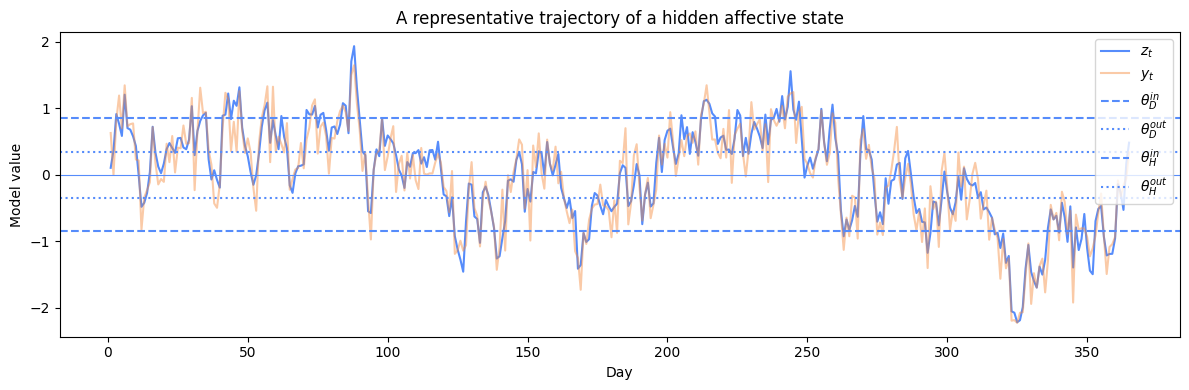

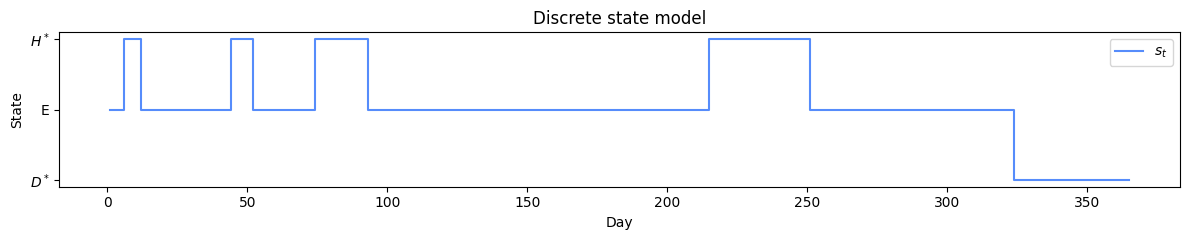

In [11]:
# ============================================================
# 10. Representative simulation
# ============================================================

params = ModelParams()

df = simulate_trajectory(
    params=params,
    seed=42,
)

summary = summarize_trajectory(df, params)
segments = extract_segments(df["state_code"])
transitions = transition_matrix(df["state_code"])

print("Podsumowanie trajektorii:")
display(pd.DataFrame([summary]))

print("Segmenty stanów:")
display(segments)

print("Macierz przejść:")
display(transitions)

fig, ax = plot_trajectory(
    df,
    params,
    title="A representative trajectory of a hidden affective state"
)

fig.savefig("figure_trajectory_z_y_thresholds.png", dpi=300, bbox_inches="tight")

fig, ax = plot_state_track(
    df,
    title="Discrete state model"
)

fig.savefig("figure_state_track.png", dpi=300, bbox_inches="tight")

#### Eksperyment: histereza vs brak histerezy

,model,days_D,days_E,days_H,n_D_segments,n_H_segments,n_transitions,mean_D_duration,mean_H_duration
0,z histerezą,66,253,46,1,3,8,66.0,15.333333
1,bez histerezy,27,305,33,2,5,14,13.5,6.600000


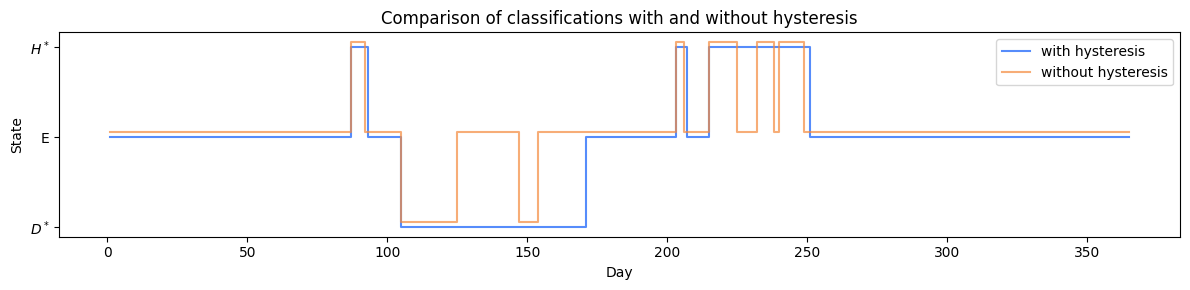

In [12]:
# ============================================================
# 11. Comparison of models with and without hysteresis
# ============================================================

params_hysteresis = ModelParams()

params_no_hysteresis = replace(
    params_hysteresis,
    theta_D_out=params_hysteresis.theta_D_in,
    theta_H_out=params_hysteresis.theta_H_in,
)

# Te same czynniki zewnętrzne i ten sam szum, żeby różnica wynikała z histerezy
rng_cov = np.random.default_rng(123)
covariates = generate_covariates(params_hysteresis.T, rng_cov)

df_hysteresis = simulate_trajectory(
    params_hysteresis,
    covariates=covariates,
    seed=999,
)

df_no_hysteresis = simulate_trajectory(
    params_no_hysteresis,
    covariates=covariates,
    seed=999,
)

summary_hysteresis = summarize_trajectory(df_hysteresis, params_hysteresis)
summary_no_hysteresis = summarize_trajectory(df_no_hysteresis, params_no_hysteresis)

comparison = pd.DataFrame([
    {"model": "z histerezą", **summary_hysteresis},
    {"model": "bez histerezy", **summary_no_hysteresis},
])

display(comparison[[
    "model",
    "days_D",
    "days_E",
    "days_H",
    "n_D_segments",
    "n_H_segments",
    "n_transitions",
    "mean_D_duration",
    "mean_H_duration",
]])

fig, ax = plot_hysteresis_comparison(
    df_hysteresis,
    df_no_hysteresis,
)

fig.savefig("figure_hysteresis_vs_no_hysteresis.png", dpi=300, bbox_inches="tight")

#### Eksperyment: kontrolowane zakłócenie X_t

,T,days_D,days_E,days_H,prop_D,prop_E,prop_H,n_D_segments,n_E_segments,n_H_segments,...,mean_H_duration,max_D_duration,max_H_duration,n_transitions,auc_negative,auc_positive,depressive_threshold_load,hypomanic_threshold_load,first_D_day,first_H_day
0,365,55,285,25,0.150685,0.780822,0.068493,1,3,1,...,25.0,55,25,4,96.405629,81.518465,41.643211,32.457555,113,224


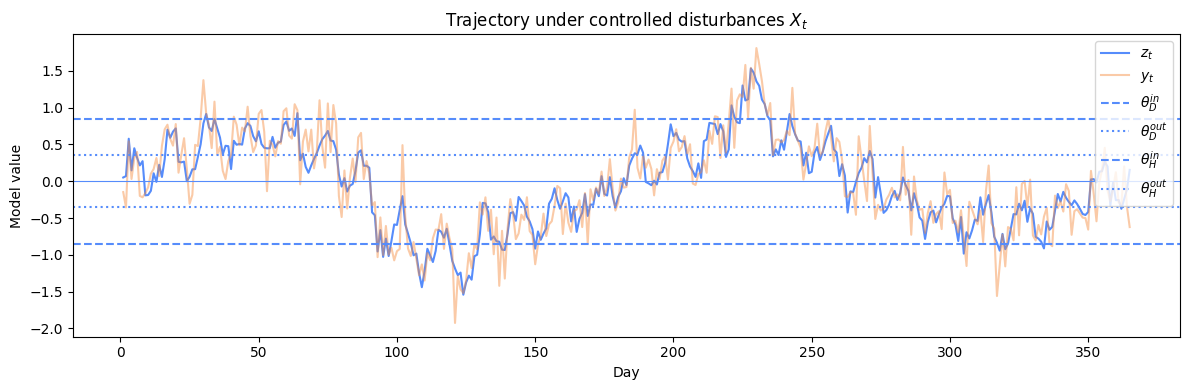

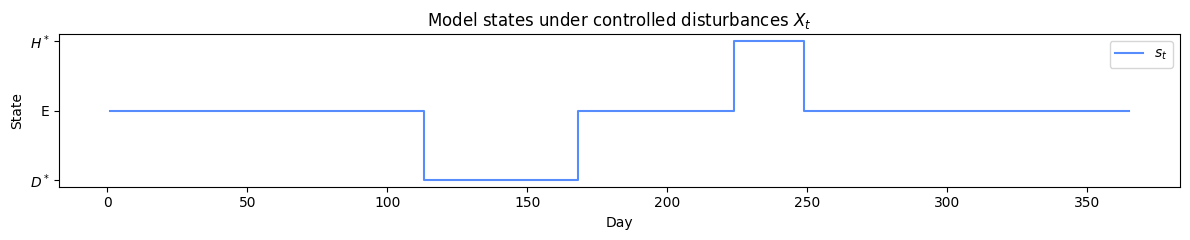

In [15]:
# ============================================================
# 12. Controlled Distress: Stress and Sleep Deprivation
# ============================================================

perturbations = [
    {
        "var": "stress",
        "start": 90,
        "end": 130,
        "magnitude": 1.5,
    },
    {
        "var": "sleep_loss",
        "start": 220,
        "end": 235,
        "magnitude": 1.8,
    },
]

controlled_covariates = make_controlled_covariates(
    T=params.T,
    perturbations=perturbations,
)

df_controlled = simulate_trajectory(
    params=params,
    covariates=controlled_covariates,
    seed=77,
)

summary_controlled = summarize_trajectory(df_controlled, params)

display(pd.DataFrame([summary_controlled]))

fig, ax = plot_trajectory(
    df_controlled,
    params,
    title="Trajectory under controlled disturbances $X_t$"
)

fig.savefig("figure_controlled_perturbation_trajectory.png", dpi=300, bbox_inches="tight")

fig, ax = plot_state_track(
    df_controlled,
    title="Model states under controlled disturbances $X_t$"
)

fig.savefig("figure_controlled_perturbation_states.png", dpi=300, bbox_inches="tight")

#### Eksperyment Monte Carlo

In [16]:
# ============================================================
# 13. Monte Carlo: many synthetic trajectories
# ============================================================

mc_results = run_monte_carlo(
    n=1000,
    params=params,
    seed=2026,
)

display(mc_results.head())

display(mc_results[[
    "days_D",
    "days_E",
    "days_H",
    "prop_D",
    "prop_E",
    "prop_H",
    "n_D_segments",
    "n_H_segments",
    "n_transitions",
    "mean_D_duration",
    "mean_H_duration",
    "auc_negative",
    "auc_positive",
]].describe().T)

mc_results.to_csv("monte_carlo_results.csv", index=False)

,T,days_D,days_E,days_H,prop_D,prop_E,prop_H,n_D_segments,n_E_segments,n_H_segments,...,max_D_duration,max_H_duration,n_transitions,auc_negative,auc_positive,depressive_threshold_load,hypomanic_threshold_load,first_D_day,first_H_day,sim_id
0,365,0,324,41,0.000000,0.887671,0.112329,0,4,3,...,0,21,6,82.697998,85.493198,30.028280,38.565727,-1,31,0
1,365,29,275,61,0.079452,0.753425,0.167123,1,6,4,...,29,46,10,99.709191,102.793435,44.980440,51.107991,125,9,1
2,365,66,227,72,0.180822,0.621918,0.197260,2,8,6,...,38,27,15,112.989091,115.531222,61.623219,59.092443,102,5,2
3,365,122,170,73,0.334247,0.465753,0.200000,2,9,6,...,66,32,16,112.966469,109.566902,64.045467,50.971984,123,20,3
4,365,44,267,54,0.120548,0.731507,0.147945,2,8,5,...,32,15,14,92.256008,95.505686,41.501843,45.691921,116,20,4


,count,mean,std,min,25%,50%,75%,max
days_D,1000.0,38.623000,23.425320,0.000000,22.000000,37.000000,53.250000,122.000000
days_E,1000.0,270.210000,34.027927,154.000000,249.000000,271.000000,295.000000,357.000000
days_H,1000.0,56.167000,17.053502,4.000000,44.000000,56.000000,67.000000,111.000000
prop_D,1000.0,0.105816,0.064179,0.000000,0.060274,0.101370,0.145890,0.334247
prop_E,1000.0,0.740301,0.093227,0.421918,0.682192,0.742466,0.808219,0.978082
prop_H,1000.0,0.153882,0.046722,0.010959,0.120548,0.153425,0.183562,0.304110
n_D_segments,1000.0,1.412000,0.743511,0.000000,1.000000,1.000000,2.000000,4.000000
n_H_segments,1000.0,4.549000,1.359208,1.000000,4.000000,5.000000,5.000000,9.000000
n_transitions,1000.0,11.858000,3.214992,4.000000,10.000000,12.000000,14.000000,24.000000
mean_D_duration,1000.0,25.699917,14.362804,0.000000,17.000000,24.000000,34.000000,76.000000


#### Analiza czułości: wpływ szumu i amplitudy wolnej komponenty

,0.030000,0.075714,0.121429,0.167143,0.212857,0.258571,0.304286,0.350000
0.200000,0.020027,0.024603,0.023918,0.024329,0.028740,0.031233,0.025397,0.023151
0.314286,0.039616,0.036055,0.031507,0.039863,0.038356,0.048575,0.039671,0.039370
0.428571,0.061014,0.058055,0.055068,0.057233,0.057479,0.066219,0.061288,0.058329
0.542857,0.094055,0.089425,0.088849,0.082137,0.088493,0.097315,0.101205,0.095233
0.657143,0.121096,0.119370,0.130795,0.122959,0.129315,0.130493,0.140356,0.135890
0.771429,0.177890,0.166356,0.178630,0.158767,0.180986,0.179452,0.190329,0.185096
0.885714,0.234740,0.230904,0.221178,0.212082,0.235315,0.224849,0.227644,0.218986
1.000000,0.261534,0.258548,0.268219,0.268082,0.258247,0.264055,0.256082,0.262247


,0.030000,0.075714,0.121429,0.167143,0.212857,0.258571,0.304286,0.350000
0.200000,0.063863,0.061479,0.067836,0.066932,0.067918,0.072356,0.074274,0.080767
0.314286,0.079041,0.077671,0.082932,0.084932,0.086164,0.083589,0.085781,0.094329
0.428571,0.104521,0.108466,0.103178,0.110082,0.111836,0.125973,0.113370,0.123945
0.542857,0.141452,0.142630,0.131945,0.135370,0.135808,0.150082,0.149973,0.152521
0.657143,0.173014,0.183041,0.172027,0.177863,0.175370,0.170274,0.176329,0.183096
0.771429,0.215808,0.215397,0.209068,0.204630,0.212411,0.214137,0.206466,0.211205
0.885714,0.243315,0.243178,0.249315,0.248219,0.249151,0.244274,0.248274,0.244603
1.000000,0.272795,0.272685,0.275342,0.272000,0.270137,0.280356,0.275562,0.276932


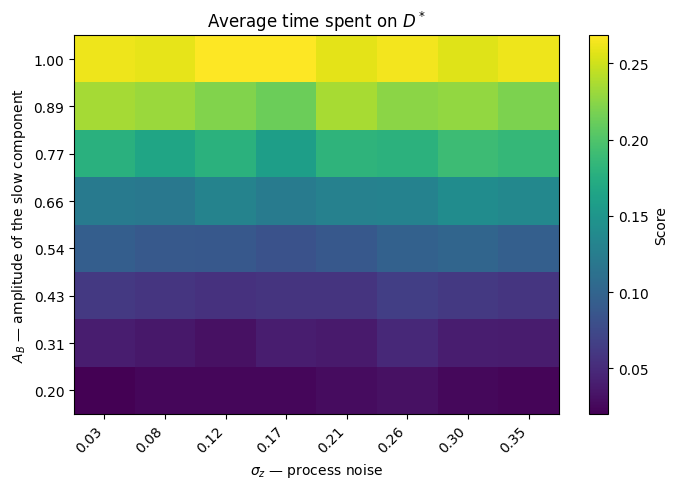

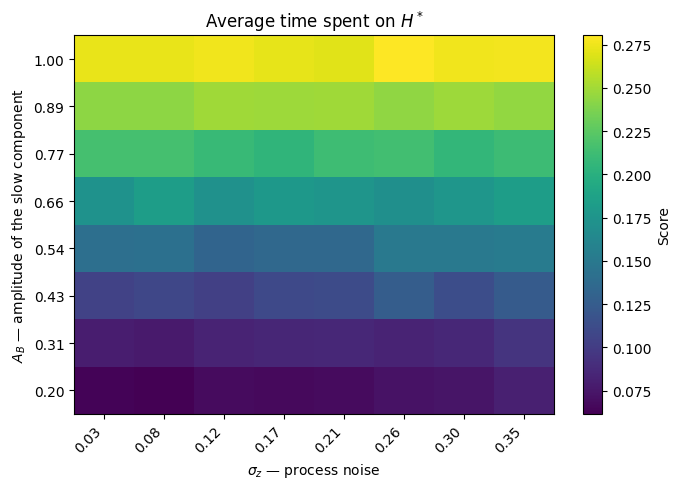

In [18]:
# ============================================================
# 14. Sensitivity analysis: sigma_z × A_B
# ============================================================

sigma_values = np.linspace(0.03, 0.35, 8)
A_B_values = np.linspace(0.20, 1.00, 8)

sensitivity_D = sensitivity_grid(
    base_params=params,
    param_x="sigma_z",
    values_x=sigma_values,
    param_y="A_B",
    values_y=A_B_values,
    outcome="prop_D",
    n_per_cell=100,
    seed=111,
)

display(sensitivity_D)

fig, ax = plot_sensitivity_heatmap(
    sensitivity_D,
    xlabel=r"$\sigma_z$ — process noise",
    ylabel=r"$A_B$ — amplitude of the slow component",
    title=r"Average time spent on $D^*$"
)

fig.savefig("figure_sensitivity_prop_D_sigma_A_B.png", dpi=300, bbox_inches="tight")


sensitivity_H = sensitivity_grid(
    base_params=params,
    param_x="sigma_z",
    values_x=sigma_values,
    param_y="A_B",
    values_y=A_B_values,
    outcome="prop_H",
    n_per_cell=100,
    seed=222,
)

display(sensitivity_H)

fig, ax = plot_sensitivity_heatmap(
    sensitivity_H,
    xlabel=r"$\sigma_z$ — process noise",
    ylabel=r"$A_B$ — amplitude of the slow component",
    title=r"Average time spent on $H^*$"
)

fig.savefig("figure_sensitivity_prop_H_sigma_A_B.png", dpi=300, bbox_inches="tight")

#### Analiza czułości: prawdopodobieństwo wystąpienia D\*i H\*

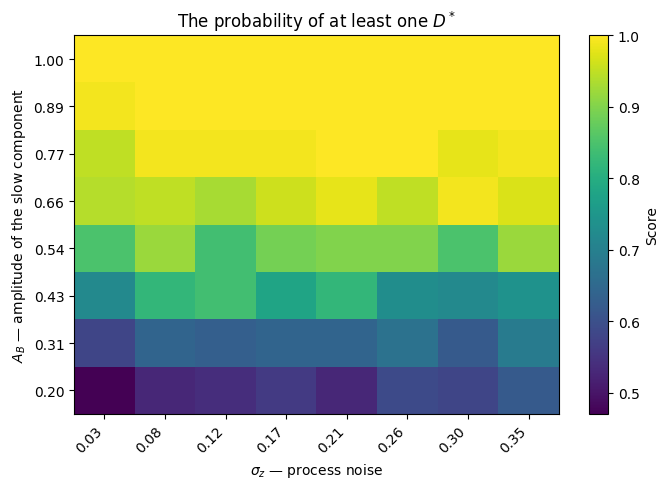

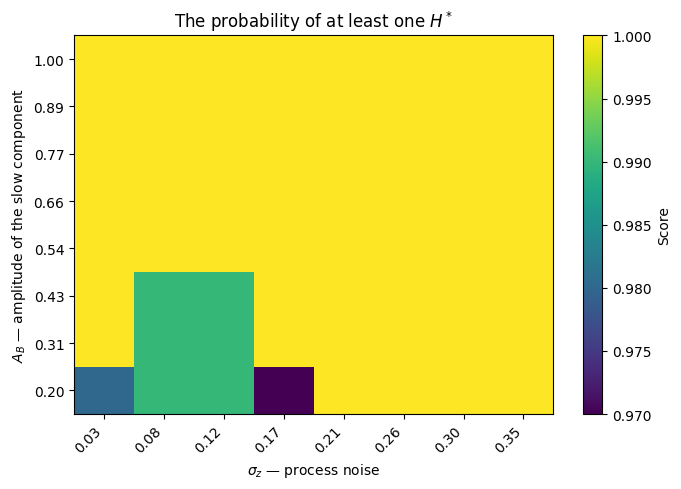

In [19]:
# ============================================================
# 15. The probability of at least one D* or H* occurring
# ============================================================

p_any_D = sensitivity_grid(
    base_params=params,
    param_x="sigma_z",
    values_x=sigma_values,
    param_y="A_B",
    values_y=A_B_values,
    outcome="p_any_D",
    n_per_cell=100,
    seed=333,
)

fig, ax = plot_sensitivity_heatmap(
    p_any_D,
    xlabel=r"$\sigma_z$ — process noise",
    ylabel=r"$A_B$ — amplitude of the slow component",
    title=r"The probability of at least one $D^*$"
)

fig.savefig("figure_sensitivity_p_any_D.png", dpi=300, bbox_inches="tight")


p_any_H = sensitivity_grid(
    base_params=params,
    param_x="sigma_z",
    values_x=sigma_values,
    param_y="A_B",
    values_y=A_B_values,
    outcome="p_any_H",
    n_per_cell=100,
    seed=444,
)

fig, ax = plot_sensitivity_heatmap(
    p_any_H,
    xlabel=r"$\sigma_z$ — process noise",
    ylabel=r"$A_B$ — amplitude of the slow component",
    title=r"The probability of at least one $H^*$"
)

fig.savefig("figure_sensitivity_p_any_H.png", dpi=300, bbox_inches="tight")